# 🦜🕸️ LangGraph RAG Agent

Welcome! This notebook demonstrates a **RAG (Retrieval-Augmented Generation) Agent** — a LangGraph
workflow where an LLM first decides whether to look up company policy documents or answer a question
directly, with each path ending independently.

| Concept | What it is | This example |
|---------|-----------|-------------|
| **State** | Shared data container | `query`, `requires_rag`, `final_answer` |
| **Router Node** | LLM classifies the query | Routes to RAG agent or general response |
| **RAG Agent** | ReAct agent with retriever tool | Searches FAISS index of HR policy docs; answer goes directly to user |
| **General Response Node** | Direct LLM answer | Handles questions that don't need policy docs |
| **Conditional Edge** | Dynamic branching | `route_decision` → `rag_agent_node` or `general_response_node` |

> **Goal:** understand how to build a LangGraph that routes queries to either a
> specialised ReAct retrieval agent or a simple general-purpose LLM node.


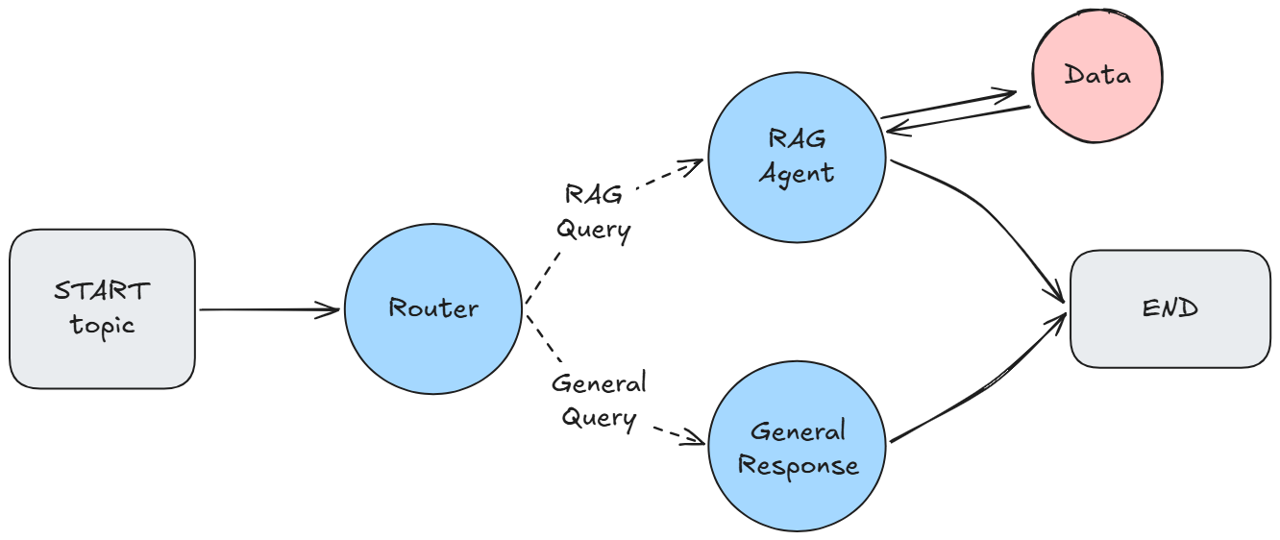

In [25]:
from IPython.display import Image, display
display(Image("images/3.png"))

<h3><center>  <div style="background-color:lightpink;border-radius:10px; padding: 10px;">Setup ⚙️</div></center></h3>

In [1]:
%pip install --quiet python-dotenv langchain langchain-core langchain-openai langchain-community langgraph faiss-cpu tiktoken


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Setting up the API keys
import sys

sys.path.insert(1, '../../')

import init_creds as creds

# Configure Azure OpenAI
AZURE_OPENAI_KEY = creds.get_api_key()
AZURE_OPENAI_ENDPOINT = creds.get_endpoint()
AZURE_OPENAI_API_VERSION = "2025-04-01-preview"
AZURE_EMBEDDING_DEPLOYMENT = "text-embedding-ada-002"  # update to your deployment name

if not AZURE_OPENAI_KEY:
    raise ValueError("No AZURE_OPENAI_KEY set for Azure OpenAI API")
if not AZURE_OPENAI_ENDPOINT:
    raise ValueError("No AZURE_OPENAI_ENDPOINT set for Azure OpenAI API")


In [6]:
import pathlib
from pydantic import BaseModel
from langchain_openai import AzureChatOpenAI, AzureOpenAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.tools.retriever import create_retriever_tool
from langchain_community.document_loaders import TextLoader
from langchain.agents import create_agent
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


In [5]:
# Chat LLM
llm = AzureChatOpenAI(
    model="gpt-4o-mini",
    azure_endpoint=AZURE_OPENAI_ENDPOINT,
    api_key=AZURE_OPENAI_KEY,
    api_version=AZURE_OPENAI_API_VERSION
)

# Embedding model for FAISS
embeddings = AzureOpenAIEmbeddings(
    model="text-embedding-3-small",
    api_key=AZURE_OPENAI_KEY,
    azure_endpoint=AZURE_OPENAI_ENDPOINT,
    api_version=AZURE_OPENAI_API_VERSION
    )

<h3><center>  <div style="background-color:skyblue;border-radius:10px; padding: 10px;">RAG Agent with LangGraph</div></center></h3>

#### 1. Company Policy Documents 📄

Three short HR policy text files are stored in the `data/` folder and loaded with
`TextLoader` from `langchain_community.document_loaders`.

| File | Topic |
|------|-------|
| `data/leave_policy.txt` | Annual, sick, and casual leave entitlements |
| `data/laptop_repair_policy.txt` | IT helpdesk process and repair coverage |
| `data/wfh_policy.txt` | Work-from-home eligibility and rules |


In [7]:
DATA_DIR = pathlib.Path("data")

policy_files = [
    DATA_DIR / "leave_policy.txt",
    DATA_DIR / "laptop_repair_policy.txt",
    DATA_DIR / "wfh_policy.txt",
]

docs = []
for file_path in policy_files:
    loader = TextLoader(str(file_path), encoding="utf-8")
    docs.extend(loader.load())

print(f"Loaded {len(docs)} policy documents")
for doc in docs:
    print(f"  • {doc.metadata['source']} ({len(doc.page_content)} chars)")


Loaded 3 policy documents
  • data/leave_policy.txt (482 chars)
  • data/laptop_repair_policy.txt (574 chars)
  • data/wfh_policy.txt (605 chars)


#### 2. FAISS Vector Store 🗄️

All policy documents are embedded with Azure OpenAI Embeddings and stored in a
**FAISS** (Facebook AI Similarity Search) in-memory index.

```python
vectorstore = FAISS.from_documents(docs, embeddings)
retriever   = vectorstore.as_retriever(search_kwargs={"k": 2})  # top-2 matches
```

The retriever is then wrapped in a LangChain **tool** so the ReAct agent can call it.


In [8]:
# Create FAISS vector store from the policy documents
vectorstore = FAISS.from_documents(docs, embeddings)

# Wrap as a retriever — fetch the top-2 most relevant chunks
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

print("FAISS vector store created.")
print(f"  Index size: {vectorstore.index.ntotal} vectors")


FAISS vector store created.
  Index size: 3 vectors


#### 3. RAG Tool & ReAct Agent 🤖

`create_retriever_tool` wraps the FAISS retriever in a LangChain tool with a name
and description the LLM reads to decide when to invoke it.

`create_agent` (from `langchain.agents`) builds a **ReAct** (Reason + Act) agent —
it loops between reasoning and tool calls until it has enough information to answer.
This is the replacement for the deprecated `langgraph.prebuilt.create_react_agent`.

```python
policy_tool = create_retriever_tool(retriever, name="...", description="...")
rag_agent   = create_agent(llm, tools=[policy_tool])
```

This agent is later called **inside a node** of the main LangGraph workflow — making it
a subgraph that handles only the retrieval step.


In [9]:
# Wrap the retriever as a named tool
policy_tool = create_retriever_tool(
    retriever,
    name="search_company_policies",
    description=(
        "Search company HR policy documents. "
        "Use this for questions about employee leave, laptop repair, "
        "or work-from-home (WFH) policy."
    ),
)

# Build a ReAct agent using create_agent (langchain.agents — replaces langgraph.prebuilt.create_react_agent)
rag_agent = create_agent(llm, tools=[policy_tool])

print("ReAct agent created with tool:", policy_tool.name)


ReAct agent created with tool: search_company_policies


#### 4. Define the State 🗂️

The `State` carries every piece of data flowing through the main pipeline.

| Field | Type | Populated by |
|-------|------|--------------|
| `query` | `str` | Caller (initial input) |
| `requires_rag` | `bool` | `router_node` |
| `final_answer` | `str` | `rag_agent_node` or `general_response_node` |


In [10]:
class State(BaseModel):
    query: str
    requires_rag: bool = False
    final_answer: str = ""


#### 5. Define the Nodes 🔧

| Node | What it does |
|------|--------------|
| `router_node` | Sends a short classification prompt; sets `requires_rag` |
| `rag_agent_node` | Invokes the ReAct agent; its answer is written directly to `final_answer` |
| `general_response_node` | Answers general questions directly with a single LLM call |


In [11]:
def router_node(state: State) -> dict:
    """Classify the query: RAG (needs policy docs) or GENERAL (answer directly)."""
    prompt = (
        "You are a routing assistant for a company HR helpdesk.\n"
        "Decide if the following query needs to look up company policy documents "
        "(about employee leave, laptop repair, or WFH policy) "
        "or if it can be answered as a general question.\n\n"
        f"Query: {state.query}\n\n"
        "Reply with ONLY the single word 'RAG' or 'GENERAL'."
    )
    response = llm.invoke(prompt)
    requires_rag = "RAG" in response.content.strip().upper()
    print(f"[Router] → {'RAG' if requires_rag else 'GENERAL'}")
    return {"requires_rag": requires_rag}


In [12]:
def rag_agent_node(state: State) -> dict:
    """Run the ReAct agent — retrieves relevant policy docs and returns the answer directly."""
    result = rag_agent.invoke({
        "messages": [("human", state.query)]
    })
    # The last message in the ReAct loop is the agent's final answer
    final_answer = result["messages"][-1].content
    print(f"[RAG Agent] Answer ({len(final_answer)} chars)")
    return {"final_answer": final_answer}


In [13]:
def general_response_node(state: State) -> dict:
    """Answer general questions directly — no policy document lookup needed."""
    response = llm.invoke(
        f"You are a helpful assistant. Answer the following question:\n\n{state.query}"
    )
    print(f"[General] Answer ({len(response.content)} chars)")
    return {"final_answer": response.content}


#### 6. Build the Graph 🔗

The routing function `route_decision` picks one of two independent paths — both lead directly to `END`.


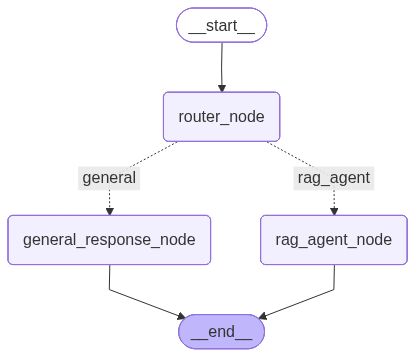

In [15]:
def route_decision(state: State) -> str:
    """Routing function — returns the name of the next node to execute."""
    return "rag_agent" if state.requires_rag else "general"


# ── Build the workflow ────────────────────────────────────────────────────
workflow = StateGraph(State)

workflow.add_node("router_node",          router_node)
workflow.add_node("rag_agent_node",       rag_agent_node)
workflow.add_node("general_response_node", general_response_node)

workflow.add_edge(START, "router_node")
workflow.add_conditional_edges(
    "router_node",
    route_decision,
    {"rag_agent": "rag_agent_node", "general": "general_response_node"},
)
workflow.add_edge("rag_agent_node",        END)
workflow.add_edge("general_response_node", END)

# Compile and visualise
graph = workflow.compile()
graph


#### 7. Run the Graph ▶️

`graph.invoke({"query": ...})` triggers the full pipeline and returns the final `State`.

We test three queries:
1. **Leave policy question** → RAG path
2. **WFH policy question** → RAG path
3. **General knowledge question** → direct path (no retrieval)


In [16]:
# Query 1: Leave policy question (RAG path)
result = graph.invoke({"query": "How many days of annual leave do I get and can I carry them forward?"})

print("=" * 65)
print("Query :", result["query"])
print("Route :", "RAG" if result["requires_rag"] else "GENERAL")
print("\nFinal Answer:")
print(result["final_answer"])


[Router] → RAG
[RAG Agent] Answer (129 chars)
Query : How many days of annual leave do I get and can I carry them forward?
Route : RAG

Final Answer:
You get 20 days of annual leave per calendar year. You can carry forward up to a maximum of 5 unused leave days to the next year.


In [17]:
# Query 2: WFH policy question (RAG path)

result = graph.invoke({"query": "Can I work from home every day? What are the requirements?"})

print("=" * 65)
print("Query  :", result["query"])
print("Route  :", "RAG" if result["requires_rag"] else "GENERAL")
print("\nFinal Answer:")
print(result["final_answer"])


[Router] → RAG
[RAG Agent] Answer (739 chars)
Query  : Can I work from home every day? What are the requirements?
Route  : RAG

Final Answer:
You cannot work from home every day according to the policy. The maximum allowed work from home days are 3 days per week, and the remaining days must be worked in the office. 

The requirements for working from home include:
- You must have completed at least 3 months of service to be eligible.
- You must work from a quiet, dedicated workspace with stable internet (minimum 10 Mbps).
- You must keep the company VPN active when accessing internal systems remotely.
- You must be available and reachable between 9 AM - 5 PM local time.
- You must attend weekly team meetings in-office.
- You need to get approval for WFH days from your direct manager via the HR portal.

If you want, I can provide more details or help with anything else.


In [18]:
# Query 3: General question (direct path — no retrieval)
result = graph.invoke({"query": "What is the capital of France?"})

print("=" * 65)
print("Query  :", result["query"])
print("Route  :", "RAG" if result["requires_rag"] else "GENERAL")
print("\nFinal Answer:")
print(result["final_answer"])


[Router] → GENERAL
[General] Answer (31 chars)
Query  : What is the capital of France?
Route  : GENERAL

Final Answer:
The capital of France is Paris.


#### 8. Conversational Memory with Query Contextualization 🧠

The stateless graph processes each query independently. To handle **follow-up questions** cleanly,
we add two things:

1. **`MemorySaver`** — persists the full message history across turns per `thread_id`
2. **`contextualize_node`** — rewrites the latest question into a *standalone query* so no other
   node ever needs to look at the message history

> **Why a dedicated contextualize node?**
>
> Without it, every node (router, RAG agent, general LLM) would need to handle history
> independently — and each could do it differently. Instead, one node does the work once and
> stores a clean `standalone_query`. The rest of the graph is identical to the stateless version.

Example:
| Turn | Raw question | Standalone query produced |
|------|-------------|--------------------------|
| 1 | *"How many days of annual leave do I get?"* | *(unchanged — already standalone)* |
| 2 | *"Can I carry any of those days forward?"* | *"Can I carry unused annual leave days forward to the next year?"* |
| 3 | *"What about WFH?"* | *"What are the work-from-home (WFH) policy requirements?"* |


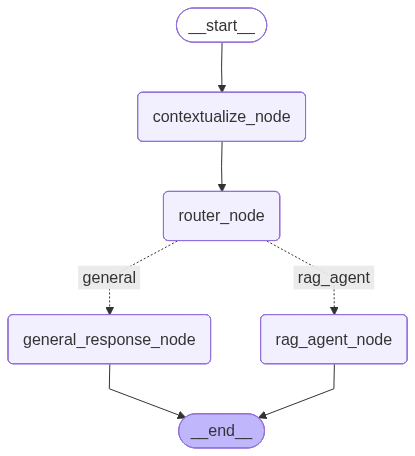

In [20]:
from typing import TypedDict, Annotated
from langchain_core.messages import HumanMessage, AIMessage, BaseMessage
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver


class MemoryState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]  # full history, grows each turn
    standalone_query: str   # context-free rewrite produced by contextualize_node
    requires_rag: bool
    final_answer: str


# 1. Contextualize node
def contextualize_node(state: MemoryState) -> dict:
    """Rewrite the latest human question into a standalone query.

    Only the human messages are passed to the LLM — the AI replies are not needed
    to rephrase the question. If there is no prior context (first turn), the question
    is returned as-is without an extra LLM call.
    """
    human_messages = [m for m in state["messages"] if isinstance(m, HumanMessage)]
    current_question = human_messages[-1].content

    # First turn — already standalone, skip the LLM call
    if len(human_messages) == 1:
        print(f"[Contextualize] First turn — using question as-is")
        return {"standalone_query": current_question}

    # Build a compact history of only the human questions for context
    prior_questions = "\n".join(
        f"Q{i+1}: {m.content}" for i, m in enumerate(human_messages[:-1])
    )

    prompt = (
        "You are a query rewriter. Given the previous questions and a follow-up question, "
        "rewrite the follow-up as a fully self-contained question that can be understood "
        "without any conversation context. If it is already standalone, return it unchanged.\n\n"
        f"Previous questions:\n{prior_questions}\n\n"
        f"Follow-up question: {current_question}\n\n"
        "Standalone question:"
    )
    resp = llm.invoke(prompt)
    standalone = resp.content.strip()
    print(f"[Contextualize] '{current_question}' → '{standalone}'")
    return {"standalone_query": standalone}


# ── 2. Router node ────────────────────────────────────────────────────────
def memory_router_node(state: MemoryState) -> dict:
    """Route using standalone_query — no history handling needed here."""
    prompt = (
        "You are a routing assistant for an HR helpdesk.\n"
        "Decide if the following query needs company policy documents "
        "(about employee leave, laptop repair, or WFH policy) "
        "or can be answered as a general question.\n\n"
        f"Query: {state['standalone_query']}\n\n"
        "Reply with ONLY 'RAG' or 'GENERAL'."
    )
    resp = llm.invoke(prompt)
    requires_rag = "RAG" in resp.content.strip().upper()
    print(f"[Router] → {'RAG' if requires_rag else 'GENERAL'}")
    return {"requires_rag": requires_rag}


# ── 3. RAG agent node ─────────────────────────────────────────────────────
def memory_rag_node(state: MemoryState) -> dict:
    """RAG agent uses the clean standalone_query — no context juggling needed."""
    result = rag_agent.invoke({
        "messages": [HumanMessage(content=state["standalone_query"])]
    })
    answer = result["messages"][-1].content
    print(f"[RAG Agent] Answer ({len(answer)} chars)")
    return {"messages": [AIMessage(content=answer)], "final_answer": answer}


# ── 4. General response node ──────────────────────────────────────────────
def memory_general_node(state: MemoryState) -> dict:
    """Direct LLM answer using the clean standalone_query."""
    response = llm.invoke(state["standalone_query"])
    answer = response.content
    print(f"[General] Answer ({len(answer)} chars)")
    return {"messages": [AIMessage(content=answer)], "final_answer": answer}


def memory_route_decision(state: MemoryState) -> str:
    return "rag_agent" if state["requires_rag"] else "general"


# ── Build memory-enabled workflow ──────────────────────────────────────────
mem_workflow = StateGraph(MemoryState)

mem_workflow.add_node("contextualize_node",    contextualize_node)
mem_workflow.add_node("router_node",           memory_router_node)
mem_workflow.add_node("rag_agent_node",        memory_rag_node)
mem_workflow.add_node("general_response_node", memory_general_node)

mem_workflow.add_edge(START, "contextualize_node")
mem_workflow.add_edge("contextualize_node", "router_node")
mem_workflow.add_conditional_edges(
    "router_node",
    memory_route_decision,
    {"rag_agent": "rag_agent_node", "general": "general_response_node"},
)
mem_workflow.add_edge("rag_agent_node",        END)
mem_workflow.add_edge("general_response_node", END)

memory_graph = mem_workflow.compile(checkpointer=MemorySaver())
memory_graph


In [22]:
# Config
config = {"configurable": {"thread_id": "123"}}

# 1st query
query_1 = "How many days of annual leave do I get?"
result_1 = memory_graph.invoke(
        {"messages": [HumanMessage(content=query_1)]},
        config,
    )
print(result_1['final_answer'])

[Contextualize] First turn — using question as-is
[Router] → RAG
[RAG Agent] Answer (207 chars)
You get 20 days of annual leave per calendar year. Unused leave can be carried forward, but only up to a maximum of 5 days. If you need any more details or have other questions about leave, feel free to ask!


In [24]:
# 2nd query (follow up)
query_2 = "Tell me more about it"
result_2 = memory_graph.invoke(
        {"messages": [HumanMessage(content=query_2)]},
        config,
    )
print(result_2['final_answer'])

[Contextualize] 'Tell me more about it' → 'Can you provide more details about the annual leave entitlements?'
[Router] → RAG
[RAG Agent] Answer (320 chars)
The annual leave entitlement is 20 days per calendar year. Unused leave can be carried forward, but only up to a maximum of 5 days. To apply for annual leave, employees need to submit their requests via the HR portal at least 3 working days in advance. If you need more details or have other questions, feel free to ask!


#### Summary 📝

| Concept | Key API | Role in this notebook |
|---------|---------|----------------------|
| **State** | `BaseModel` | Carries query, routing flag, and final answer |
| **Router Node** | `llm.invoke(classification_prompt)` | Decides RAG vs. general path |
| **Conditional Edge** | `add_conditional_edges(src, fn, map)` | Branches to `rag_agent_node` or `general_response_node` |
| **FAISS Store** | `FAISS.from_documents(docs, embeddings)` | In-memory vector index over policy documents |
| **Retriever Tool** | `create_retriever_tool(retriever, ...)` | Exposes FAISS search as a callable tool |
| **ReAct Agent** | `create_agent(llm, tools)` *(from `langchain.agents`)* | Retrieves policy docs and answers directly |
| **General Response Node** | `llm.invoke(prompt)` | Answers general questions with a single LLM call |
| **Invoke** | `graph.invoke({"query": ...})` | Runs the full pipeline, returns final State |
